# Urinary Metabolomics Biomarker Discovery for Cancer Cachexia
## Part 1 of 3: Data Quality & Chemometric Exploration

**The challenge.** Cachexia (cancer-associated muscle wasting) affects up to 80 % of advanced cancer patients and is usually diagnosed only after substantial muscle loss. A non-invasive urine test that flags it early would be clinically valuable. Can the urinary metabolome tell cachexic from non-cachexic patients, and which metabolites carry the signal?

**Dataset.** Real, public ¹H-NMR urinary metabolomics data from cancer patients:
- 77 patients: **47 cachexic**, **30 control** (non-cachexic cancer patients)
- 63 quantified metabolites (concentrations, µM)
- Source: Eisner R. *et al.* (2011) "Learning to predict cancer-associated skeletal muscle wasting from ¹H-NMR profiles of urinary metabolites", *Metabolomics* 7, 25–34. [doi:10.1007/s11306-010-0232-9](https://doi.org/10.1007/s11306-010-0232-9). Distributed as an example dataset by [MetaboAnalyst](https://www.metaboanalyst.ca/).

**Goals for this notebook**
1. Load and quality-check the data (missing values, class balance, distributions)
2. Choose a transformation (log₂) and check urine dilution, a classic pre-analytical confounder
3. Unsupervised PCA: do the groups separate *before* any labels are used?
4. Univariate screening with **Welch t-tests + Benjamini–Hochberg FDR** (volcano plot)


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("../../data/human_cachexia.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
PALETTE = {"Cachexic": "#E74C3C", "Control": "#3498DB"}

SOURCE_URL = "https://rest.xialab.ca/api/download/metaboanalyst/human_cachexia.csv"

if DATA.exists():
    df = pd.read_csv(DATA)
else:
    # First run: fetch the public MetaboAnalyst copy and standardise the schema
    raw = pd.read_csv(SOURCE_URL)
    df = raw.rename(columns={"Patient ID": "Sample", "Muscle loss": "Condition"})
    df["Condition"] = df["Condition"].str.capitalize()
    DATA.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(DATA, index=False)

y = df["Condition"]
X = df.drop(columns=["Sample", "Condition"])
print(f"{X.shape[0]} patients x {X.shape[1]} metabolites")
print("Class balance:", y.value_counts().to_dict())
print(f"Majority-class baseline accuracy: {y.value_counts(normalize=True).max():.1%}")


77 patients x 63 metabolites
Class balance: {'Cachexic': 47, 'Control': 30}
Majority-class baseline accuracy: 61.0%


## 1. Data quality checks

Missing values:        0
Non-positive values:   0  (log transform is safe)
Concentration range:   0.79 - 33860 uM
Dynamic range:         4.6 orders of magnitude
Metabolites with skew > 1: 61 / 63


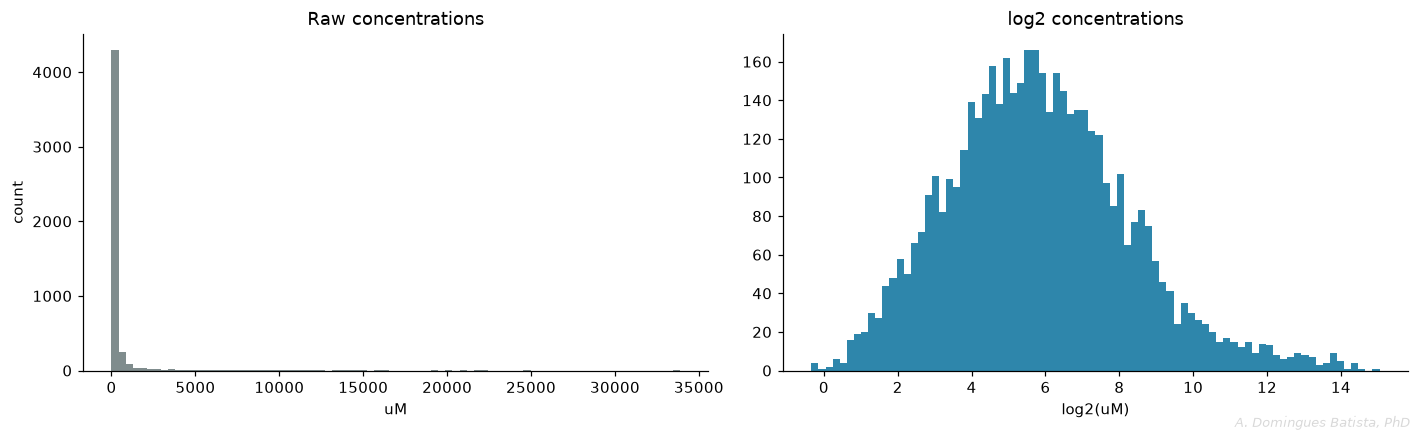

In [2]:
print(f"Missing values:        {X.isna().sum().sum()}")
print(f"Non-positive values:   {(X <= 0).sum().sum()}  (log transform is safe)")
print(f"Concentration range:   {X.min().min():.2f} - {X.max().max():.0f} uM")
print(f"Dynamic range:         {np.log10(X.max().max() / X.min().min()):.1f} orders of magnitude")
skew = X.skew()
print(f"Metabolites with skew > 1: {(skew > 1).sum()} / {len(skew)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(X.values.ravel(), bins=80, color="#7f8c8d")
axes[0].set(title="Raw concentrations", xlabel="uM", ylabel="count")
axes[1].hist(np.log2(X.values.ravel()), bins=80, color="#2E86AB")
axes[1].set(title="log2 concentrations", xlabel="log2(uM)")
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.show()


**Decision: log₂ transform.** Concentrations span several orders of magnitude and almost every metabolite is right-skewed; log₂ makes the distributions roughly symmetric and turns fold-changes into differences.

**Urine dilution.** Urine concentration varies several-fold with hydration, so chemometric pipelines usually apply probabilistic quotient normalisation (PQN). Before normalising blindly, we check whether the dilution factor itself differs between groups. If it does, every metabolite will look "up" in one group for a reason that has nothing to do with specific biochemistry.

In [3]:
def pqn(frame: pd.DataFrame) -> pd.DataFrame:
    """Probabilistic quotient normalisation against the median spectrum."""
    ref = frame.median(axis=0)
    quotients = frame.div(ref, axis=1).median(axis=1)
    return frame.div(quotients, axis=0)

dilution = X.div(X.median(axis=0), axis=1).median(axis=1)
print(f"PQN dilution factors: median {dilution.median():.2f}, range {dilution.min():.2f}-{dilution.max():.2f}")
print("Mean dilution factor by group:", dilution.groupby(y).mean().round(2).to_dict())

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score
print(f"Mann-Whitney p (dilution, cachexic vs control): {mannwhitneyu(dilution[y == 'Cachexic'], dilution[y == 'Control']).pvalue:.1e}")
print(f"ROC-AUC of the dilution factor ALONE:            {roc_auc_score(y == 'Cachexic', dilution):.2f}")

X_log = np.log2(X)
X_log_pqn = np.log2(pqn(X))


PQN dilution factors: median 1.14, range 0.22-4.31
Mean dilution factor by group: {'Cachexic': 1.53, 'Control': 0.79}
Mann-Whitney p (dilution, cachexic vs control): 1.8e-04
ROC-AUC of the dilution factor ALONE:            0.75


## 2. PCA: unsupervised view

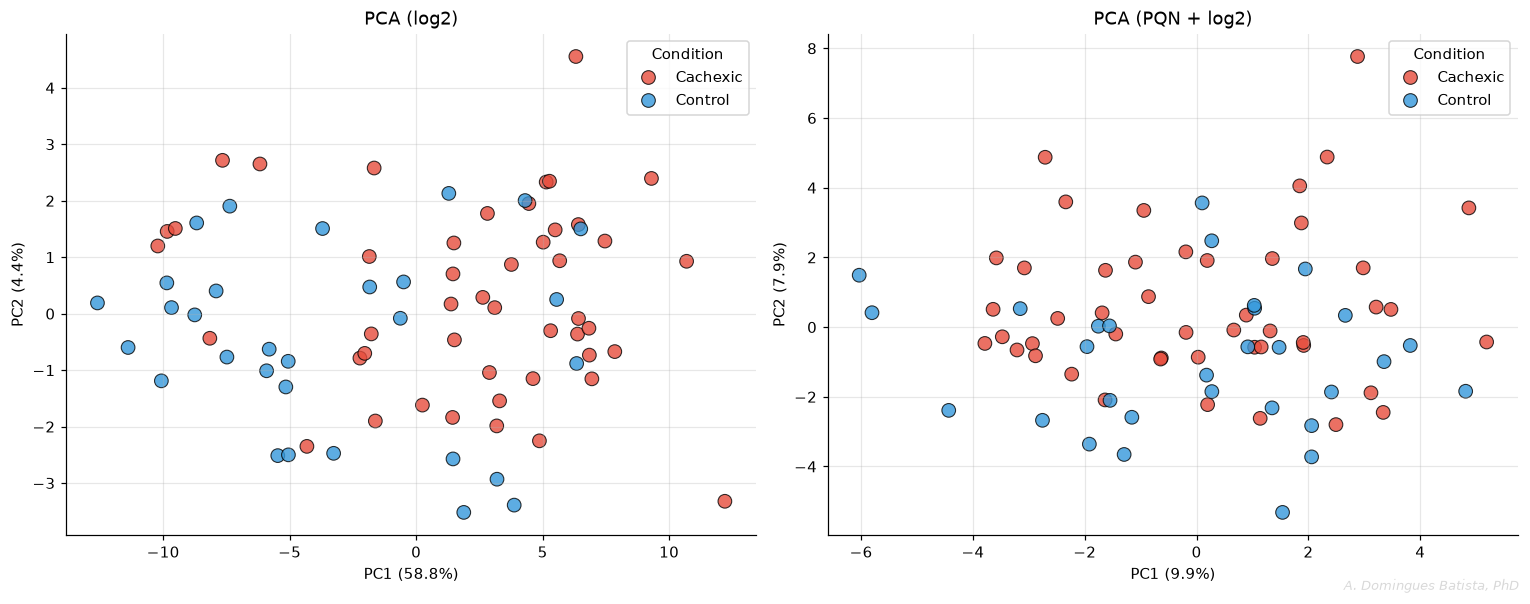

Mean PC1 score by group: {'Cachexic': 2.16, 'Control': -3.39}


In [4]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (title, data) in zip(axes, [("log2", X_log), ("PQN + log2", X_log_pqn)]):
    pca = PCA(n_components=2).fit(StandardScaler().fit_transform(data))
    scores = pca.transform(StandardScaler().fit_transform(data))
    sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=y, palette=PALETTE, s=80,
                    edgecolor="k", alpha=0.8, ax=ax)
    ev = pca.explained_variance_ratio_
    ax.set(title=f"PCA ({title})", xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})")
    ax.grid(alpha=0.3)
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.savefig(FIG_DIR / "pca.png", bbox_inches="tight"); plt.show()

pc1 = PCA(n_components=1).fit_transform(StandardScaler().fit_transform(X_log))[:, 0]
print("Mean PC1 score by group:", pd.Series(pc1).groupby(y.values).mean().round(2).to_dict())


**Key finding: cachexic urine is globally more concentrated.** The PQN dilution factor is about 2x higher in cachexic patients (p ≈ 2e-4), and on its own it separates the groups with ROC-AUC ≈ 0.75. In the log₂ PCA, PC1 is essentially this "overall concentration" axis. After PQN, the groups overlap almost completely.

Whether this reflects biology (e.g., altered fluid balance or catabolic load in cachexia) or a pre-analytical effect (collection time, hydration) cannot be resolved from these data. Either way, it has to be reported, and the univariate screen below is run **both ways**.

## 3. Univariate screening: Welch t-test + FDR

In [5]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

cach, ctrl = X_log[y == "Cachexic"], X_log[y == "Control"]
t, p = ttest_ind(cach, ctrl, equal_var=False)
res = pd.DataFrame({
    "Metabolite": X.columns,
    "log2FC": (cach.mean() - ctrl.mean()).values,
    "p_value": p,
})
res["q_value"] = multipletests(res["p_value"], method="fdr_bh")[1]
res["-log10(p)"] = -np.log10(res["p_value"])

# Same test after PQN dilution correction
cach_n, ctrl_n = X_log_pqn[y == "Cachexic"], X_log_pqn[y == "Control"]
res["log2FC_pqn"] = (cach_n.mean() - ctrl_n.mean()).values
res["q_value_pqn"] = multipletests(ttest_ind(cach_n, ctrl_n, equal_var=False)[1], method="fdr_bh")[1]
res = res.sort_values("p_value").reset_index(drop=True)
res.to_csv("univariate_results.csv", index=False)

for label, q, fc in [("raw log2", "q_value", "log2FC"), ("PQN-corrected", "q_value_pqn", "log2FC_pqn")]:
    sig = res[q] < 0.05
    print(f"{label:>14}: {sig.sum():2d} / {len(res)} metabolites at q < 0.05 "
          f"(up {(sig & (res[fc] > 0)).sum()}, down {(sig & (res[fc] < 0)).sum()})")
print()
print("Significant after dilution correction:",
      res.loc[res.q_value_pqn < 0.05, ["Metabolite", "log2FC_pqn", "q_value_pqn"]].round(3).to_dict("records"))
res.head(10).round(4)


      raw log2: 54 / 63 metabolites at q < 0.05 (up 54, down 0)
 PQN-corrected:  2 / 63 metabolites at q < 0.05 (up 0, down 2)

Significant after dilution correction: [{'Metabolite': 'Isoleucine', 'log2FC_pqn': -0.553, 'q_value_pqn': 0.031}, {'Metabolite': 'Uracil', 'log2FC_pqn': -0.693, 'q_value_pqn': 0.031}]


,Metabolite,log2FC,p_value,q_value,-log10(p),log2FC_pqn,q_value_pqn
0,Glucose,1.6177,0.0000,0.0002,5.5911,0.5956,0.1364
1,Adipate,1.4050,0.0000,0.0003,4.9937,0.3829,0.2263
2,Quinolinate,1.2383,0.0000,0.0003,4.9102,0.2162,0.4866
3,Leucine,1.1488,0.0000,0.0003,4.7518,0.1268,0.7290
4,Valine,1.1725,0.0000,0.0003,4.5733,0.1504,0.3311
5,myo-Inositol,1.4763,0.0000,0.0003,4.5515,0.4542,0.2225
6,3-Hydroxyisovalerate,1.5120,0.0000,0.0003,4.3667,0.4899,0.2263
7,"N,N-Dimethylglycine",1.4887,0.0000,0.0003,4.3535,0.4666,0.2048
8,3-Hydroxybutyrate,1.2691,0.0001,0.0004,4.2262,0.2470,0.4482
9,Succinate,1.7809,0.0001,0.0004,4.1515,0.7588,0.1488


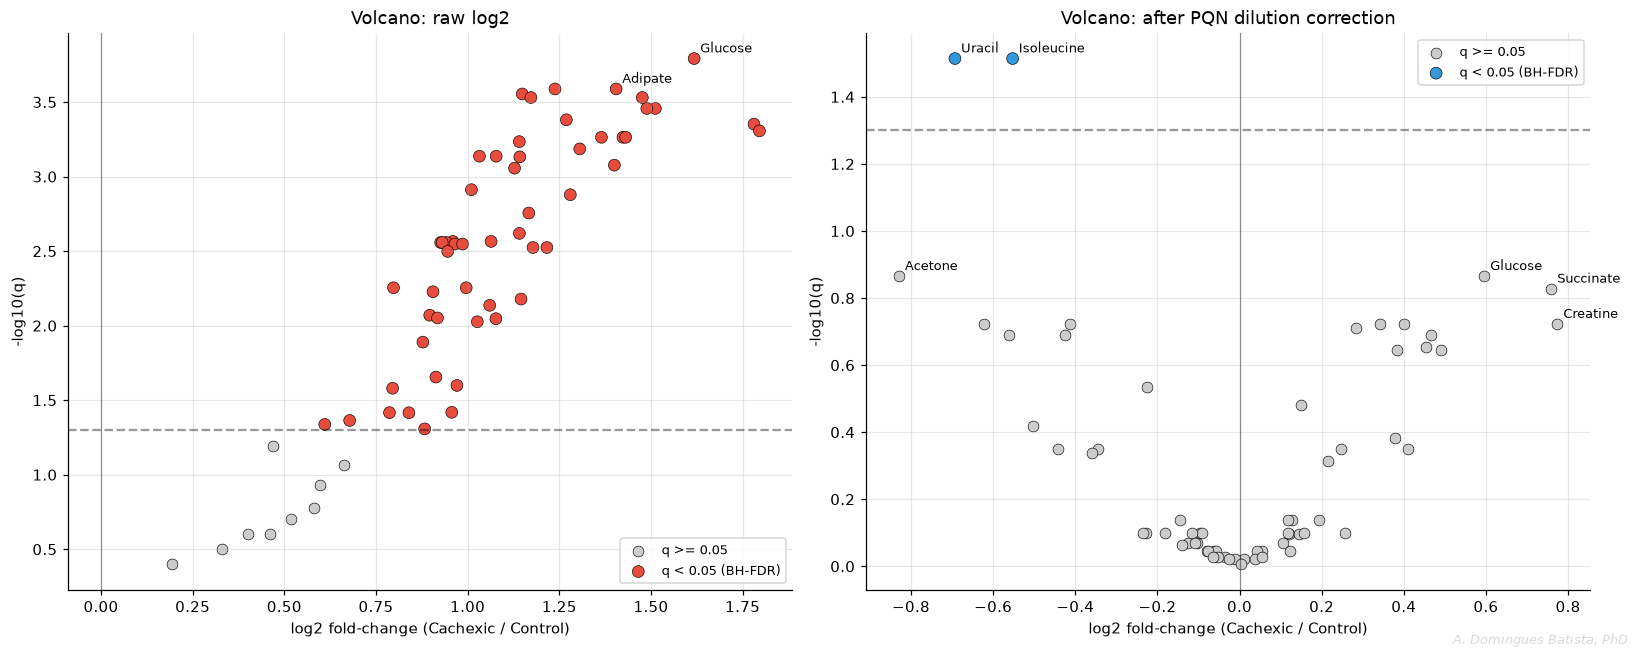

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (title, fc, q) in zip(axes, [("raw log2", "log2FC", "q_value"), ("after PQN dilution correction", "log2FC_pqn", "q_value_pqn")]):
    sig = res[q] < 0.05
    ax.scatter(res.loc[~sig, fc], -np.log10(res.loc[~sig, q]), c="#CCCCCC", s=50, edgecolor="k", lw=0.4, label="q >= 0.05")
    ax.scatter(res.loc[sig, fc], -np.log10(res.loc[sig, q]), c=np.where(res.loc[sig, fc] > 0, "#E74C3C", "#3498DB"),
               s=60, edgecolor="k", lw=0.4, label="q < 0.05 (BH-FDR)")
    ax.axhline(-np.log10(0.05), ls="--", c="k", alpha=0.4); ax.axvline(0, c="k", lw=0.8, alpha=0.4)
    for _, r in res.nsmallest(2 if q == "q_value" else 6, q).iterrows():
        ax.annotate(r.Metabolite, (r[fc], -np.log10(r[q])), fontsize=8.5, xytext=(4, 4), textcoords="offset points")
    ax.set(xlabel="log2 fold-change (Cachexic / Control)", ylabel="-log10(q)", title=f"Volcano: {title}")
    ax.legend(fontsize=8.5); ax.grid(alpha=0.3)
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.savefig(FIG_DIR / "volcano.png", bbox_inches="tight"); plt.show()


## Summary

- **Data quality:** real clinical data, no missing values, moderate class imbalance (47 : 30, majority baseline 61 %), so balanced accuracy and ROC-AUC are reported from here on.
- **The dominant signal is global urine concentration.** Without normalisation, 54 of 63 metabolites are FDR-significant, *all* higher in cachexia, which is the fingerprint of a dilution difference, not of 54 independent biomarkers.
- **After PQN, only uracil and isoleucine remain significant** (both relatively *lower* in cachexia). Those are the genuinely metabolite-specific changes.
- **Implication for modelling:** Notebook 2 benchmarks every model against a one-number "dilution factor only" baseline, so we can see how much the full metabolite profile really adds.
